# Red de dinastías medievales — limpieza y validación de relaciones

Este notebook toma los dos CSV exportados para Gephi (nodos y relaciones, scrapeados de Wikidata) y:

1. **Perfila** los datos y documenta la convención de dirección de las aristas.
2. **Limpia los nodos**: nodos vacíos (`genid`), etiquetas placeholder, años y ubicaciones estimadas (`*`) y la columna `casa`, que mezcla dinastías con títulos.
3. **Limpia las aristas**: autolazos, duplicados, extremos huérfanos y pares con relaciones contradictorias.
4. **Valida la genealogía**: cantidad de padres/madres por persona, saltos generacionales, contradicciones de género, ciclos, coherencia cronológica y hermanos sin progenitor común.
5. **Corrige** lo que puede corregirse de forma segura y **marca** el resto (`sospechosa`, `motivo`) para revisarlo en Gephi.
6. **Exporta** `nodos_limpios.csv`, `relaciones_limpias.csv` e `incidencias.csv`.

> **Criterios acordados**
> - Se aplican todas las correcciones automáticas del script: saltos generacionales, fusiones de duplicados evidentes y resoluciones de confianza alta.
> - Se **eliminan** los datos que generan incidencias de: *varios padres*, *varias madres*, *hermanos sin progenitor común*, *posible persona duplicada* y *label placeholder* (sección 7).
> - **Las fechas no se usan como criterio**: muchas son aproximadas y otras confunden nacimiento con muerte. La cronología se muestra solo como información.
> - *Hermano + cónyuge* se acepta como relación válida.

In [1]:
from pathlib import Path
import re, unicodedata
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

# ---------------- Configuración ----------------
DATA_DIR      = Path(".")                       # carpeta con los CSV
NODOS_CSV     = DATA_DIR / "nodos_gephi_optimizados.csv"
RELACIONES_CSV= DATA_DIR / "relaciones_gephi_optimizadas.csv"
OUT_DIR       = DATA_DIR / "salida"
OUT_DIR.mkdir(exist_ok=True)

# Umbrales cronológicos (en años) entre nacimiento de progenitor e hijo
EDAD_MIN_PADRE = 12
EDAD_MAX_PADRE = 70   # para madres se usa EDAD_MAX_MADRE
EDAD_MAX_MADRE = 55
GENERACION     = 28   # años promedio por generación (para re-estimar fechas)

# Si True, las relaciones simétricas (hermano, cónyuge) se exportan una sola vez como no dirigidas
COLAPSAR_SIMETRICAS = True

## 1. Carga y perfil inicial
Se lee todo como texto (`dtype=str`) para que años como `0569` no pierdan el cero ni se conviertan en float.

In [2]:
nodos_raw = pd.read_csv(NODOS_CSV, dtype=str, keep_default_na=False)
rel_raw   = pd.read_csv(RELACIONES_CSV, dtype=str, keep_default_na=False)

print("Nodos:", nodos_raw.shape, "| Relaciones:", rel_raw.shape)
display(nodos_raw.head())
display(rel_raw.head())
print(rel_raw["Label"].value_counts())

Nodos: (18807, 5) | Relaciones: (82463, 3)


,Id,Label,casa,epoca,ubicacion
0,Q7419,Emperador Yangdi,dinastía Sui,0569,Chang'an
1,Q9458,Mahoma,Banu Háshim,0571,La Meca
2,Q39619,Ali Ibn Abi Talib,príncipe de los creyentes,0599,La Meca
3,Q22968293,Samson,príncipe franco,0573,Desconocido
4,Q22968296,Dagobert,príncipe franco,0580,Desconocido


,Source,Target,Label
0,Q7419,Q7418,padre
1,Q7419,Q1066855,madre
2,Q7419,Q8251583,conyuge
3,Q8251583,Q7419,conyuge
4,Q7419,Q16603620,hermano


Label
hermano    50679
conyuge    15178
padre       9278
madre       7328
Name: count, dtype: int64


In [3]:
def perfil(df):
    return pd.DataFrame({
        "valores_unicos": df.nunique(),
        "vacios": (df == "").sum(),
        "Desconocido/a": df.isin(["Desconocido", "Desconocida"]).sum(),
        "con_asterisco": df.apply(lambda s: s.str.endswith("*").sum()),
        "ejemplo": df.iloc[0],
    })
perfil(nodos_raw)

,valores_unicos,vacios,Desconocido/a,con_asterisco,ejemplo
Id,18807,0,0,0,Q7419
Label,17880,0,0,0,Emperador Yangdi
casa,1378,0,8487,0,dinastía Sui
epoca,1502,0,3478,5009,0569
ubicacion,1705,0,13476,2407,Chang'an


## 2. Convención de dirección de las aristas (importante)

Hay que confirmar qué significa `Source → Target` antes de validar nada. La primera fila es:

`Q7419 (Emperador Yangdi) → Q7418 (Yang Jian), padre`

Yang Jian **es el padre** de Yangdi, así que la convención es:

| Arista | Significado |
|---|---|
| `A → B, padre` | **B es el padre de A** (Source = hijo, Target = progenitor) |
| `A → B, madre` | B es la madre de A |
| `A ↔ B, hermano / conyuge` | relación simétrica (viene duplicada en ambos sentidos) |

**Consecuencia en Gephi:** un nodo con muchas aristas `padre` **entrantes** es en realidad un padre con muchos hijos, no un hijo con muchos padres. Del mismo modo, un nodo con 1 o 2 aristas `padre`/`madre` **salientes** es una persona con sus progenitores. Si el análisis anterior se hizo mirando el grado de entrada, es probable que de ahí venga la impresión de "muchos padres y un solo hijo". La celda siguiente lo muestra con casos concretos. Los errores reales (personas con 2+ padres) se tratan en la sección 5.

In [4]:
lab = nodos_raw.set_index("Id")["Label"]
pm_raw = rel_raw[rel_raw.Label.isin(["padre", "madre"])]

ent = pm_raw.groupby("Target").size().rename("aristas_padre/madre_entrantes (= hijos)")
sal = pm_raw.groupby("Source").size().rename("aristas_padre/madre_salientes (= progenitores)")
grados = pd.concat([ent, sal], axis=1).fillna(0).astype(int)
grados.insert(0, "Label", lab)
print("Nodos con más aristas padre/madre ENTRANTES -> son progenitores con muchos hijos:")
display(grados.sort_values(grados.columns[1], ascending=False).head(8))

Nodos con más aristas padre/madre ENTRANTES -> son progenitores con muchos hijos:


,Label,aristas_padre/madre_entrantes (= hijos),aristas_padre/madre_salientes (= progenitores)
Q7486,Song Huizong,68,2
Q9746,Xuanzong de Tang,29,2
Q9701,Li Shimin,26,2
Q9700,Gaozu de Tang,23,2
Q7483,Song Shenzong,22,2
Q206123,Haroldo I de Noruega,21,3
Q9760,Shun Zong,20,2
Q9761,Xian Zong,20,2


## 3. Limpieza de nodos

### 3.1 Texto: espacios, Unicode y placeholders

In [5]:
nodos = nodos_raw.copy()

def norm_txt(s: str) -> str:
    s = unicodedata.normalize("NFC", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

for c in nodos.columns:
    nodos[c] = nodos[c].map(norm_txt)

# Nodos en blanco de Wikidata (blank nodes): Id hash y Label = URL .well-known/genid
es_genid = nodos.Label.str.contains("well-known/genid", regex=False) | ~nodos.Id.str.fullmatch(r"Q\d+")
print("Nodos genid (vacíos):", es_genid.sum())

# Etiquetas que no identifican a nadie
PLACEHOLDER_RE = r"(?i)^(?:nn|n|n\.\s*n\.|\?+|unknown.*|desconocid[oa].*|q\d+)$|\(\?\)"
nodos["label_placeholder"] = nodos.Label.str.contains(PLACEHOLDER_RE, regex=True)
nodos["label_es_qid"]      = nodos.Label.str.fullmatch(r"Q\d+")
print("Labels placeholder:", nodos.label_placeholder.sum(), "| de ellos Q-ids sin resolver:", nodos.label_es_qid.sum())
display(nodos.loc[nodos.label_placeholder, "Label"].value_counts().head(15))

Nodos genid (vacíos): 13
Labels placeholder: 627 | de ellos Q-ids sin resolver: 456


Label
NN                                            72
unknown wife (?)                               3
n                                              3
Maud (?)                                       3
unknown daughter von Hohenlohe-Weikersheim     3
Adele (?)                                      2
unknown (?)                                    2
Joan (?)                                       2
Q95139853                                      1
Q95139861                                      1
Q16075293                                      1
Q16075302                                      1
Q16260931                                      1
Q16603439                                      1
Q16603599                                      1
Name: count, dtype: int64

### 3.2 `epoca` → año numérico + flags de estimación y precisión
El `*` indica un año **estimado/imputado** (no viene de Wikidata). Se separa en dos columnas y `Desconocido` pasa a nulo.

Además, muchos años "reales" son redondos (1100, 1150, 1250…): son fechas con precisión de **siglo o medio siglo** en Wikidata. Se marcan con `anio_impreciso`, porque generan falsos positivos en la validación cronológica.

Años reales múltiplos de 50 o x01: 25.1% (esperable si fueran exactos: ~3%)
año real            10320
año estimado (*)     5009
sin año              3478
dtype: int64
Rango: 550 - 1449


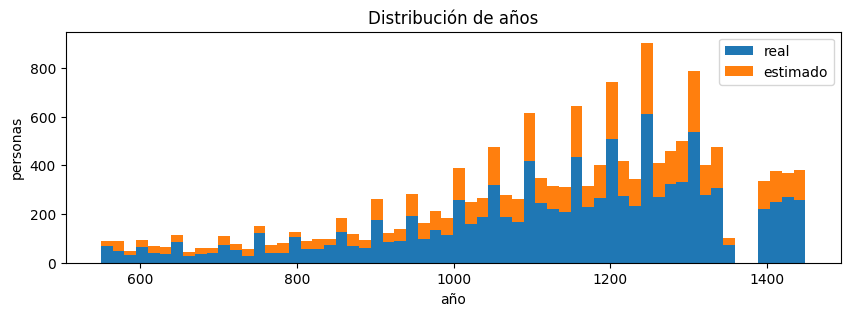

In [6]:
nodos["anio_estimado"] = nodos.epoca.str.endswith("*")
nodos["anio"] = pd.to_numeric(nodos.epoca.str.rstrip("*"), errors="coerce").astype("Int64")
nodos.loc[nodos.anio.isna(), "anio_estimado"] = False

# Años de baja precisión: Wikidata guarda fechas con precisión de siglo/medio siglo como 1100, 1150, 1201...
# Si los años fueran exactos, ~2% serían múltiplos de 50. Aquí son muchos más.
nodos["anio_impreciso"] = nodos.anio.notna() & ((nodos.anio % 50 == 0) | (nodos.anio % 100 == 1))
reales_ = nodos.anio.notna() & ~nodos.anio_estimado
print(f"Años reales múltiplos de 50 o x01: {nodos.loc[reales_, 'anio_impreciso'].mean():.1%} (esperable si fueran exactos: ~3%)")

print(pd.Series({
    "año real": (nodos.anio.notna() & ~nodos.anio_estimado).sum(),
    "año estimado (*)": nodos.anio_estimado.sum(),
    "sin año": nodos.anio.isna().sum(),
}))
print("Rango:", nodos.anio.min(), "-", nodos.anio.max())

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist([nodos.loc[~nodos.anio_estimado, "anio"].dropna(), nodos.loc[nodos.anio_estimado, "anio"].dropna()],
        bins=60, stacked=True, label=["real", "estimado"])
ax.set_xlabel("año"); ax.set_ylabel("personas"); ax.legend(); ax.set_title("Distribución de años")
plt.show()

### 3.3 `ubicacion` → texto limpio + flag de estimación

In [7]:
nodos["ubicacion_estimada"] = nodos.ubicacion.str.endswith("*")
nodos["ubicacion"] = nodos.ubicacion.str.rstrip("*").str.strip().replace({"Desconocido": pd.NA, "": pd.NA})
print("Ubicaciones estimadas:", nodos.ubicacion_estimada.sum(), "| sin ubicación:", nodos.ubicacion.isna().sum())
nodos.ubicacion.value_counts().head(10)

Ubicaciones estimadas: 2407 | sin ubicación: 13476


ubicacion
Chang'an          189
Kaifeng           130
Constantinopla     92
Kioto              85
Praga              64
Heian-kyō          61
Kiev               54
Cracovia           49
París              46
Nápoles            39
Name: count, dtype: int64

### 3.4 `casa`: separar dinastía de título nobiliario
La columna mezcla dinastías (`Casa de Borgoña`, `House of Li`) con cargos (`conde`, `duque`, `reina consorte`) y con Q-ids sin resolver. Se divide en `casa` y `titulo` con una heurística. Conviene revisar `casas_sin_clasificar` y ajustar las listas.

In [8]:
CASA_RE   = r"(?i)\b(casa|dinast[íi]a|house|familia|family|clan|dynasty|linaje|genji|heishi|piast|ætta)\b|(idas|ídas|íes|ids|ici|igeri)$"
TITULO_RE = (r"(?i)^(conde|condesa|count|countess|duque|duquesa|duke|duchess|pr[íi]ncipe|princesa|prince|princess|"
             r"imperial princess|reina|rey|king|queen|emperador|emperatriz|emperor|empress|margrave|marqu[ée]s|"
             r"graf|vizconde|bar[óo]n|jarl|kniaz|lord|lady|señor|señora|landgrave|burgrave|burggraf|juez|"
             r"infante|infanta|consorte|obispo|príncipe-obispo|khan|kan|sultán|califa)\b")

def clasificar_casa(v):
    if v in ("", "Desconocida", "Desconocido"):
        return pd.NA, pd.NA, "vacía"
    if re.fullmatch(r"Q\d+", v):
        return pd.NA, pd.NA, "qid"
    if re.search(CASA_RE, v):
        return v, pd.NA, "casa"
    if re.search(TITULO_RE, v):
        return pd.NA, v, "titulo"
    return v, pd.NA, "sin_clasificar"   # se conserva como casa

res = nodos.casa.map(clasificar_casa)
nodos["casa_original"] = nodos.casa
nodos["casa"]   = res.str[0]
nodos["titulo"] = res.str[1]
nodos["casa_tipo"] = res.str[2]
display(nodos.casa_tipo.value_counts())
print("Títulos más frecuentes:"); display(nodos.titulo.value_counts().head(10))
casas_sin_clasificar = nodos.loc[nodos.casa_tipo == "sin_clasificar", "casa_original"].value_counts()
print("Revisar a mano (se dejaron como casa):"); display(casas_sin_clasificar.head(25))

casa_tipo
vacía             8487
titulo            4557
casa              4059
sin_clasificar    1474
qid                230
Name: count, dtype: int64

Títulos más frecuentes:


titulo
conde             1362
duque              294
princesa           277
duquesa            174
Kniaz              172
reina              108
reina consorte      96
margrave            79
príncipe            77
graf                69
Name: count, dtype: int64

Revisar a mano (se dejaron como casa):


casa_original
Hårfagreætta                        42
Borjigin                            41
Οίκος των Ασκάνια-Βρανδεμβούργου    35
Comneno                             35
Piastas de Silesia                  33
Hokke                               31
Piasts of Mazovia                   29
Piasts of Greater Poland            25
Weimar-Orlamünde                    23
Piasts of Kuyavia                   22
Rúrikovich                          21
Głogów-Żagań Piasts                 19
Piasts of Teschen                   18
Del Vasto                           16
Onggirat                            15
Sturlungar                          15
Ibelín                              14
Piastas de Opole                    14
Cantacuceno                         12
Lichtenberg                         12
Rurikids of Polotsk                 12
Nanke                               12
Arnulfinos                          11
Håløygætten                         11
Casal de Pallars                    11
Name: count

### 3.5 Posibles duplicados de persona
Mismo nombre normalizado y años a ≤ 5 de distancia. Wikidata tiene muchas entidades duplicadas (dos Q-ids para la misma persona). **No se fusionan automáticamente**: se listan para revisión.

In [9]:
def clave_nombre(s):
    s = unicodedata.normalize("NFKD", s.lower())
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    return re.sub(r"[^a-z0-9 ]", "", s).strip()

nodos["nombre_norm"] = nodos.Label.map(clave_nombre)
cand = nodos[~nodos.label_placeholder & ~es_genid & nodos.anio.notna()]
m = cand.merge(cand, on="nombre_norm", suffixes=("_a", "_b"))
m = m[(m.Id_a < m.Id_b) & ((m.anio_a - m.anio_b).abs() <= 5)]
posibles_duplicados = m[["Id_a", "Id_b", "Label_a", "Label_b", "anio_a", "anio_b", "casa_original_a", "casa_original_b"]]
print("Pares candidatos a duplicado:", len(posibles_duplicados))
posibles_duplicados.head(15)

Pares candidatos a duplicado: 60


,Id_a,Id_b,Label_a,Label_b,anio_a,anio_b,casa_original_a,casa_original_b
458,Q4309077,Q4313077,Li Xiao,Li Xiao,650,645,House of Li,House of Li
475,Q38976923,Q45474239,Li Xu,Li Xu,650,650,House of Li,House of Li
656,Q11098128,Q11098130,Li Yu,Li Yu,745,750,House of Li,House of Li
889,Q11095399,Q11096908,Li Xian,Li Xian,750,750,House of Li,House of Li
901,Q11097672,Q11098106,Li Shu,Li Shu,750,745,House of Li,House of Li
905,Q11097694,Q11097743,Li Xun,Li Xun,750,750,House of Li,House of Li
906,Q11097694,Q11098084,Li Xun,Li Xun,750,750,House of Li,House of Li
913,Q11097704,Q11097728,Li Zong,Li Zong,750,750,House of Li,House of Li
946,Q11097743,Q11098084,Li Xun,Li Xun,750,750,House of Li,House of Li
985,Q15914778,Q16603623,Li Shi,Li Shi,750,750,House of Li,House of Li


## 4. Limpieza de aristas

In [10]:
rel = rel_raw.copy()
for c in rel.columns:
    rel[c] = rel[c].map(norm_txt)
rel["Label"] = rel.Label.str.lower()

log = {}   # registro de cuántas aristas se eliminan en cada paso

ids_genid = set(nodos.loc[es_genid, "Id"])
n0 = len(rel); rel = rel[~rel.Source.isin(ids_genid) & ~rel.Target.isin(ids_genid)]; log["con nodo genid"] = n0 - len(rel)
n0 = len(rel); rel = rel[rel.Source != rel.Target];                                    log["autolazos"] = n0 - len(rel)
n0 = len(rel); rel = rel.drop_duplicates(["Source", "Target", "Label"]);               log["duplicadas"] = n0 - len(rel)
ids_validos = set(nodos.loc[~es_genid, "Id"])
n0 = len(rel); rel = rel[rel.Source.isin(ids_validos) & rel.Target.isin(ids_validos)]; log["extremo inexistente"] = n0 - len(rel)

# Las relaciones simétricas deben estar en ambos sentidos
SIM = ["hermano", "conyuge"]
asim = []
for t in SIM:
    e = rel[rel.Label == t]; s = set(zip(e.Source, e.Target))
    asim += [(a, b, t) for a, b in s if (b, a) not in s]
log["simétricas sin su inversa (se completan)"] = len(asim)
if asim:
    rel = pd.concat([rel, pd.DataFrame([(b, a, t) for a, b, t in asim], columns=["Source", "Target", "Label"])])

nodos = nodos[~es_genid].copy()
print(pd.Series(log, name="aristas"))
print("Aristas restantes:", len(rel))

con nodo genid                              26
autolazos                                    1
duplicadas                                   0
extremo inexistente                          0
simétricas sin su inversa (se completan)     0
Name: aristas, dtype: int64
Aristas restantes: 82436


### 4.1 Pares de personas con relaciones contradictorias
Un mismo par no puede ser a la vez *hermanos y cónyuges*, *padre-hijo y hermanos*, etc. (en el medievo hubo matrimonios entre parientes, pero no entre hermanos de primer grado salvo casos muy puntuales). Se marcan para revisión.

In [11]:
def pares(tipos):
    e = rel[rel.Label.isin(tipos)]
    return set(frozenset(p) for p in zip(e.Source, e.Target))

P_par, P_her, P_con = pares(["padre", "madre"]), pares(["hermano"]), pares(["conyuge"])
contradicciones = []
for nombre, A, B in [("hermano+conyuge", P_her, P_con), ("progenitor+hermano", P_par, P_her), ("progenitor+conyuge", P_par, P_con)]:
    for p in A & B:
        a, b = sorted(p)
        contradicciones.append({"tipo": nombre, "A": a, "B": b, "Label_A": lab.get(a), "Label_B": lab.get(b)})
contradicciones = pd.DataFrame(contradicciones)
print(contradicciones.tipo.value_counts() if len(contradicciones) else "sin contradicciones")
contradicciones.head(20)

tipo
hermano+conyuge       13
progenitor+hermano    12
progenitor+conyuge     4
Name: count, dtype: int64


,tipo,A,B,Label_A,Label_B
0,hermano+conyuge,Q7244845,Q837590,Princess Tajima,Prince Takechi
1,hermano+conyuge,Q1046438,Q233224,Prince Kusakabe,Emperatriz Genmei
2,hermano+conyuge,Q11597250,Q349281,Princess Hashihito no Anahobe,Emperador Yōmei
3,hermano+conyuge,Q314846,Q7244811,Emperador Kanmu,Sakahito
4,hermano+conyuge,Q177517,Q3154069,Fujiwara no Fuhito,Ioe no Iratsume
5,hermano+conyuge,Q15614112,Q357249,Shōshi-naishinnō,Emperador Juntoku
6,hermano+conyuge,Q11425620,Q17191458,Kinshi-naishinnō,Imperial Prince Atsuyoshi
7,hermano+conyuge,Q298057,Q316637,Emperatriz Suiko,Bidatsu
8,hermano+conyuge,Q11669919,Q374136,Koshi-naishinnō,Emperador Junna
9,hermano+conyuge,Q11434304,Q353558,Ōyake-naishinnō,Emperador Heizei


## 5. Validación de la genealogía

Se construye el grafo dirigido **progenitor → hijo** (la inversa del CSV, que es la forma natural de recorrer una genealogía).

In [12]:
pm = rel[rel.Label.isin(["padre", "madre"])].copy()
pm["hijo"], pm["progenitor"] = pm.Source, pm.Target
G = nx.DiGraph()
G.add_nodes_from(nodos.Id)
G.add_edges_from(zip(pm.progenitor, pm.hijo))

anio = nodos.set_index("Id")["anio"]
anio_est = nodos.set_index("Id")["anio_estimado"]
lab = nodos.set_index("Id")["Label"]

resumen = pd.DataFrame(index=nodos.Id)
resumen["Label"] = lab
resumen["n_padres"] = pm[pm.Label == "padre"].groupby("hijo").size()
resumen["n_madres"] = pm[pm.Label == "madre"].groupby("hijo").size()
resumen["n_hijos"]  = pm.groupby("progenitor").size()
resumen = resumen.fillna({"n_padres": 0, "n_madres": 0, "n_hijos": 0}).astype({"n_padres": int, "n_madres": int, "n_hijos": int})
pd.crosstab(resumen.n_padres, resumen.n_madres, margins=True)

n_madres,0,1,2,3,4,All
n_padres,,,,,,
0,9437,118,1,0,1,9557
1,2062,7100,32,2,0,9196
2,13,22,6,0,0,41
All,11512,7240,39,2,1,18794


### 5.1 Personas con más de un padre o más de una madre
Es el error que se sospechaba. Las causas típicas en datos de Wikidata son:

- **Salto generacional**: uno de los "padres" es en realidad el abuelo (es ancestro del otro padre). Se puede corregir automáticamente.
- **Padre biológico vs. adoptivo/legal**, o propuestas historiográficas distintas: requiere revisión manual.
- **Duplicado**: dos Q-ids para el mismo padre.

In [13]:
multi = []
for rol, maximo in [("padre", 1), ("madre", 1)]:
    e = pm[pm.Label == rol]
    g = e.groupby("hijo").progenitor.apply(list)
    for hijo, progs in g[g.map(len) > maximo].items():
        # ¿alguno de los progenitores es ancestro de otro? -> el ancestro es un salto generacional
        saltos = [p for p in progs if any(q != p and nx.has_path(G, p, q) for q in progs)]
        # ¿son posibles duplicados (mismo nombre normalizado)?
        nombres = [clave_nombre(lab.get(p, "")) for p in progs]
        multi.append({
            "hijo": hijo, "Label_hijo": lab.get(hijo), "anio_hijo": anio.get(hijo), "rol": rol,
            "progenitores": progs, "Labels": [lab.get(p) for p in progs],
            "anios": [anio.get(p) for p in progs],
            "salto_generacional": saltos,
            "posible_duplicado": len(set(nombres)) < len(nombres),
        })
multi = pd.DataFrame(multi)
multi["diagnostico"] = np.select(
    [multi.salto_generacional.map(len) > 0, multi.posible_duplicado],
    ["salto generacional (corregible)", "progenitor duplicado"], "revisión manual")
print(multi.groupby(["rol", "diagnostico"]).size())
multi.sort_values(["diagnostico", "rol"]).head(30)

rol    diagnostico                    
madre  revisión manual                    42
padre  revisión manual                    26
       salto generacional (corregible)    15
dtype: int64


,hijo,Label_hijo,anio_hijo,rol,progenitores,Labels,anios,salto_generacional,posible_duplicado,diagnostico
41,Q11419381,Kashi-naishinnō,1050,madre,"[Q106436058, Q110579932]","[In no Ue, Minamoto no Nagatsune's daughter]","[994, 994]",[],False,revisión manual
42,Q11498376,Keishi-naishinnō,850,madre,"[Q11605125, Q17230096]","[Ki no Shizuko, Fujiwara no Konshi/Imako]","[827, 827]",[],False,revisión manual
43,Q11501719,Noriko-naishinno,1336,madre,"[Q11657998, Q106687761]","[Ano Renshi, Kitabatake Akiko]","[1288, 1328]",[],False,revisión manual
44,Q125454,Richlind,946,madre,"[Q237510, Q25487193]","[Edith de Wessex, Ida de Schwaben]","[910, 930]",[],False,revisión manual
45,Q1338775,Ratbold II de Provença,1000,madre,"[Q2994830, Q113987149]","[Constance of Vienne, Emilde]","[920, 1000]",[],False,revisión manual
46,Q1459919,Frederic II of Vianden,1135,madre,"[Q76196133, Q110562389]","[Mathilde de Haute-Lorraine, NN]","[1115, 1115]",[],False,revisión manual
47,Q15615597,Svyatopolk Mstislavich,1115,madre,"[Q2241510, Q2616032]","[Riquilda de Polonia, reina de Suecia, Cristina Ingesdotter de Suecia]","[1116, 1100]",[],False,revisión manual
48,Q15927754,Zhao Kai,1101,madre,"[Q8251757, Q19653851]","[Wang Shi, Q19653851]","[1082, 1082]",[],False,revisión manual
49,Q178007,Federico I de Lorena,1143,madre,"[Q91003, Q60650591]","[Judith de Hohenstaufen, Bertha]","[1133, 1123]",[],False,revisión manual
50,Q18614876,Marguerite of Roucy,1045,madre,"[Q18606694, Q58674087]","[Alix de Roucy, Adela de Roucy]","[1010, 1010]",[],False,revisión manual


### 5.2 Contradicciones de género
Si una persona aparece como `padre` de alguien y como `madre` de otro, uno de los dos roles está mal. También se infiere el sexo por el rol de progenitor y se marcan matrimonios donde ambos cónyuges tienen el mismo sexo inferido, que suele indicar un rol de progenitor mal cargado.

In [14]:
como_padre = set(pm.loc[pm.Label == "padre", "progenitor"])
como_madre = set(pm.loc[pm.Label == "madre", "progenitor"])
genero_conflicto = sorted(como_padre & como_madre)
print("Personas que son padre y madre a la vez:", [(i, lab.get(i)) for i in genero_conflicto])

sexo = pd.Series(pd.NA, index=nodos.Id, dtype="object")
sexo[list(como_padre - como_madre)] = "M"
sexo[list(como_madre - como_padre)] = "F"
nodos["sexo_inferido"] = nodos.Id.map(sexo)

con = rel[(rel.Label == "conyuge") & (rel.Source < rel.Target)].copy()
con["sA"], con["sB"] = con.Source.map(sexo), con.Target.map(sexo)
conyuges_mismo_sexo = con[con.sA.notna() & (con.sA == con.sB)].assign(
    Label_A=lambda d: d.Source.map(lab), Label_B=lambda d: d.Target.map(lab))
print("Matrimonios con mismo sexo inferido:", len(conyuges_mismo_sexo))
conyuges_mismo_sexo.head(10)

Personas que son padre y madre a la vez: [('Q103560123', 'Aelfthryth'), ('Q5561986', 'Gille Brigte, Earl of Strathearn')]
Matrimonios con mismo sexo inferido: 1


,Source,Target,Label,sA,sB,Label_A,Label_B
27649,Q141611136,Q3356544,conyuge,F,F,Tora Torbergsdatter,Tora Torbergsdatter


### 5.3 Ciclos genealógicos
Nadie puede ser su propio ancestro. Un ciclo indica una arista invertida.

In [15]:
es_dag = nx.is_directed_acyclic_graph(G)
ciclos = [] if es_dag else list(nx.simple_cycles(G))
print("¿Genealogía acíclica?", es_dag, "| ciclos:", len(ciclos))
for c in ciclos[:10]:
    print(" -> ".join(lab.get(x, x) for x in c))

¿Genealogía acíclica? True | ciclos: 0


### 5.4 Coherencia cronológica progenitor-hijo (solo informativo)
> Las fechas no son confiables (aproximadas y, en algunos casos, de muerte en lugar de nacimiento). Esta sección **no marca ni elimina nada**: solo sirve para dimensionar el problema.

Se usa **solo** años reales (sin `*`), porque los estimados se calcularon a partir de los propios vínculos y no sirven para validarlos.

- `diferencia < 0`: el hijo nació antes que el progenitor → probable **arista invertida** o año mal cargado.
- `0 ≤ diferencia < EDAD_MIN_PADRE`: biológicamente imposible.
- `diferencia > EDAD_MAX_*`: improbable → posible salto generacional (abuelo cargado como padre).

Si alguno de los dos años es **impreciso** (redondo), la incidencia se etiqueta `(año impreciso)` y baja de severidad: casi siempre es una fecha con precisión de siglo y no un error del vínculo.

Aristas con ambos años reales: 11337
problema_cronologico
progenitor demasiado mayor (año impreciso)     654
hijo anterior al progenitor (año impreciso)    581
progenitor demasiado joven (año impreciso)     528
progenitor demasiado joven                     104
hijo anterior al progenitor                     25
progenitor demasiado mayor                      23
Name: count, dtype: int64


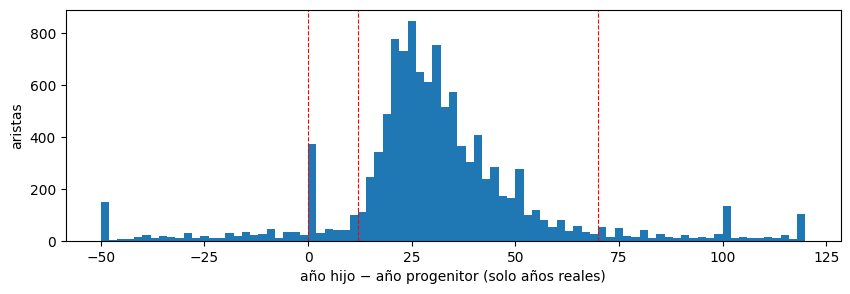

,Label_hijo,anio_hijo,Label,Label_prog,anio_prog,diferencia,problema_cronologico
34791,Alp Arslan d'Alep,1097,padre,Fakhr al-Mulk Radwan,1180,-83.0,hijo anterior al progenitor
41904,Sultan Shah,1108,padre,Fakhr al-Mulk Radwan,1180,-72.0,hijo anterior al progenitor
18282,Arnulfo I de Flandes,889,madre,Elfrida,940,-51.0,hijo anterior al progenitor
18143,"Adelolf, Count of Boulogne",891,madre,Elfrida,940,-49.0,hijo anterior al progenitor
66631,Costanza Morosini,1275,padre,Michele Morosini,1308,-33.0,hijo anterior al progenitor
54408,Margiris,1236,padre,Butvydas,1261,-25.0,hijo anterior al progenitor
64406,"Constance, Duchess of Wodzisław",1255,madre,"Anna of Masovia, Duchess of Racibórz",1270,-15.0,hijo anterior al progenitor
65361,Giovanna Novella Malaspina,1268,padre,Spinetta Malaspina,1282,-14.0,hijo anterior al progenitor
22311,"Wickman, Count of Hamaland",910,padre,Meginhard IV of Hamaland,923,-13.0,hijo anterior al progenitor
64409,"Constance, Duchess of Wodzisław",1255,padre,Przemysław of Racibórz,1268,-13.0,hijo anterior al progenitor


In [16]:
pm["anio_hijo"], pm["anio_prog"] = pm.hijo.map(anio), pm.progenitor.map(anio)
pm["est_hijo"], pm["est_prog"]   = pm.hijo.map(anio_est), pm.progenitor.map(anio_est)
pm["diferencia"] = (pm.anio_hijo - pm.anio_prog).astype("float")
reales = pm[pm.diferencia.notna() & ~pm.est_hijo & ~pm.est_prog].copy()

max_edad = np.where(reales.Label == "madre", EDAD_MAX_MADRE, EDAD_MAX_PADRE)
reales["problema_cronologico"] = np.select(
    [reales.diferencia < 0, reales.diferencia < EDAD_MIN_PADRE, reales.diferencia > max_edad],
    ["hijo anterior al progenitor", "progenitor demasiado joven", "progenitor demasiado mayor"], "")
impreciso = nodos.set_index("Id")["anio_impreciso"]
reales["anio_impreciso"] = reales.hijo.map(impreciso) | reales.progenitor.map(impreciso)
reales.loc[(reales.problema_cronologico != "") & reales.anio_impreciso, "problema_cronologico"] += " (año impreciso)"
crono = reales[reales.problema_cronologico != ""].assign(
    Label_hijo=lambda d: d.hijo.map(lab), Label_prog=lambda d: d.progenitor.map(lab))

print("Aristas con ambos años reales:", len(reales))
print(crono.problema_cronologico.value_counts())

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(reales.diferencia.clip(-50, 120), bins=85)
for x in (0, EDAD_MIN_PADRE, EDAD_MAX_PADRE): ax.axvline(x, color="red", lw=0.8, ls="--")
ax.set_xlabel("año hijo − año progenitor (solo años reales)"); ax.set_ylabel("aristas")
plt.show()
crono[~crono.anio_impreciso][["Label_hijo", "anio_hijo", "Label", "Label_prog", "anio_prog", "diferencia", "problema_cronologico"]].sort_values("diferencia").head(20)

### 5.5 Años estimados incoherentes y re-estimación
Varios años con `*` quedaron mal imputados (por ejemplo, un padre "nacido" después que su hijo). Se re-estiman propagando desde los años **reales**: hijo ≈ progenitor + `GENERACION`, progenitor ≈ hijo − `GENERACION`, hermanos/cónyuges ≈ mismo año. Se itera hasta que no haya cambios. El año original se conserva en `anio_original`.

In [17]:
pm_all = pm.copy()
est = pm_all[pm_all.diferencia.notna() & (pm_all.est_hijo | pm_all.est_prog)]
est_incoherentes = est[(est.diferencia < EDAD_MIN_PADRE) | (est.diferencia > EDAD_MAX_PADRE)]
print("Aristas con algún año estimado fuera de rango:", len(est_incoherentes), "de", len(est))

def reestimar(nodos, pm, rel, gen=GENERACION, iters=30):
    fijo = nodos.set_index("Id").pipe(lambda d: d.anio.where(~d.anio_estimado)).astype("float")
    actual = fijo.copy()
    sim = rel[rel.Label.isin(["hermano", "conyuge"])]
    for _ in range(iters):
        cand = pd.concat([
            (pm.progenitor.map(actual) + gen).groupby(pm.hijo).mean(),
            (pm.hijo.map(actual) - gen).groupby(pm.progenitor).mean(),
            sim.Target.map(actual).groupby(sim.Source).mean(),
        ], axis=1).mean(axis=1)
        nuevo = actual.fillna(cand)
        if nuevo.notna().sum() == actual.notna().sum():
            break
        actual = nuevo
    return actual.round().astype("Int64")

nodos["anio_original"] = nodos.anio
nuevo_anio = reestimar(nodos, pm, rel)
mask = nodos.anio_estimado | nodos.anio.isna()
nodos.loc[mask, "anio"] = nodos.loc[mask, "Id"].map(nuevo_anio).values
nodos.loc[mask & nodos.anio.notna(), "anio_estimado"] = True

cambios = nodos[mask & (nodos.anio != nodos.anio_original)]
print("Años estimados modificados:", len(cambios), "| años nuevos donde no había:", (mask & nodos.anio_original.isna() & nodos.anio.notna()).sum())
cambios[["Id", "Label", "anio_original", "anio"]].assign(delta=lambda d: d.anio - d.anio_original).sort_values("delta", key=abs, ascending=False).head(10)

Aristas con algún año estimado fuera de rango: 762 de 3544
Años estimados modificados: 2587 | años nuevos donde no había: 3477


,Id,Label,anio_original,anio,delta
14319,Q8193954,Aldonza Alfonso de León,1101,1226,125
12996,Q51826532,Emelota de Jericó,1001,1090,89
13024,Q12286004,Maria Komnene,1001,1089,88
14029,Q61982952,Q61982952,1101,1186,85
15299,Q75382865,Irmgard von Hohenlohe,1200,1285,85
11181,Q112264983,Ailona Aznárez de Aragón,770,848,78
12925,Q15649521,Alicia de Montlhéry,1100,1022,-78
15572,Q75453214,Lady Joan de Burgh,1201,1271,70
12256,Q513495,Andrónico Ducas,950,1018,68
12277,Q16985749,Immilla of Turin,950,1017,67


### 5.6 Hermanos sin progenitor común
Si dos personas son `hermano` y ambas tienen progenitores cargados pero no comparten ninguno, la arista es sospechosa.

El caso inverso también se revisa: dos personas que comparten progenitor pero no tienen arista `hermano` son **hermanos faltantes**. Es información que el scraping no trajo y que puede inferirse. No se buscan grupos "cerrados" de hermanos, porque los medios hermanos (muy comunes con varias consortes) rompen esa regla de forma legítima.

In [18]:
progs_de = pm.groupby("hijo").progenitor.apply(set)
her = rel[(rel.Label == "hermano") & (rel.Source < rel.Target)].copy()

def estado(a, b):
    pa, pb = progs_de.get(a, set()), progs_de.get(b, set())
    if not pa or not pb: return "sin datos"
    return "comparten progenitor" if pa & pb else "NO comparten"
her["estado"] = [estado(a, b) for a, b in zip(her.Source, her.Target)]
print(her.estado.value_counts())
hermanos_sin_comun = her[her.estado == "NO comparten"].assign(
    Label_A=lambda d: d.Source.map(lab), Label_B=lambda d: d.Target.map(lab))
display(hermanos_sin_comun.head(10))

pares_her = set(frozenset(p) for p in zip(her.Source, her.Target))
faltan = set()
for p, hijos in pm.groupby("progenitor").hijo:
    hijos = sorted(set(hijos))
    for i in range(len(hijos)):
        for j in range(i + 1, len(hijos)):
            if frozenset((hijos[i], hijos[j])) not in pares_her:
                faltan.add((hijos[i], hijos[j]))
hermanos_faltantes = pd.DataFrame(sorted(faltan), columns=["A", "B"]).assign(
    Label_A=lambda d: d.A.map(lab), Label_B=lambda d: d.B.map(lab))
print("Pares que comparten progenitor sin arista 'hermano':", len(hermanos_faltantes))
hermanos_faltantes.head(10)

estado
comparten progenitor    13455
sin datos               11815
NO comparten               68
Name: count, dtype: int64


,Source,Target,Label,estado,Label_A,Label_B
1700,Q1655899,Q309919,hermano,NO comparten,Regintrud,Clodoveo II
2885,Q233224,Q836214,hermano,NO comparten,Emperatriz Genmei,Princess Tōchi
2924,Q537139,Q883726,hermano,NO comparten,Tasilón II de Baviera,Lantpert of Bavaria
5671,Q233224,Q858974,hermano,NO comparten,Emperatriz Genmei,Takata
5675,Q233224,Q985724,hermano,NO comparten,Emperatriz Genmei,Taki-no-himemiko
5677,Q233224,Q985739,hermano,NO comparten,Emperatriz Genmei,Princess Ōku
5686,Q1362200,Q233224,hermano,NO comparten,Príncipe Toneri,Emperatriz Genmei
5697,Q233224,Q7244631,hermano,NO comparten,Emperatriz Genmei,Hatsusebe
5705,Q233224,Q7244845,hermano,NO comparten,Emperatriz Genmei,Princess Tajima
6014,Q1655899,Q266756,hermano,NO comparten,Regintrud,Adela


Pares que comparten progenitor sin arista 'hermano': 2056


,A,B,Label_A,Label_B
0,Q1001446,Q470177,Budivoi,Enrique de los abodritas
1,Q100454117,Q11623225,Fujiwara no Moromoto,Fujiwara no Moroie
2,Q100760,Q2896943,"Frederick II, Count of Diessen",Berchtold II of Diessen
3,Q1010336,Q248335,Burchard IV. im Hassegau,Dietrich I of Wettin
4,Q101167275,Q16201115,Lucy of Hereford,Mahel de Hereford
5,Q101167275,Q3438962,Lucy of Hereford,Roger FitzMiles
6,Q101167275,Q3638894,Lucy of Hereford,Bertha of Hereford
7,Q101167275,Q5721277,Lucy of Hereford,Enrique de Hereford
8,Q101167275,Q7966512,Lucy of Hereford,Walter de Hereford
9,Q101384,Q62978447,Enrique I de Inglaterra,Ágata de Normandía


### 5.7 Proporciones atípicas por persona
Se marcan personas con un número de cónyuges, hijos o hermanos muy alto, usando un umbral robusto (percentil 99.9). Muchas son reales (emperadores chinos y japoneses con decenas de consortes e hijos), pero conviene revisarlas.

In [19]:
resumen["n_conyuges"] = rel[rel.Label == "conyuge"].groupby("Source").size()
resumen["n_hermanos"] = rel[rel.Label == "hermano"].groupby("Source").size()
resumen = resumen.fillna(0).astype({c: int for c in ["n_conyuges", "n_hermanos"]})
umbrales = resumen[["n_hijos", "n_conyuges", "n_hermanos"]].quantile(0.999).round()
print("Umbrales p99.9:", umbrales.to_dict())
atipicos = resumen[(resumen[umbrales.index] > umbrales).any(axis=1)]
atipicos.sort_values("n_hijos", ascending=False).head(15)

Umbrales p99.9: {'n_hijos': 12.0, 'n_conyuges': 10.0, 'n_hermanos': 68.0}


,Label,n_padres,n_madres,n_hijos,n_conyuges,n_hermanos
Id,,,,,,
Q7486,Song Huizong,1,1,68,9,23
Q9746,Xuanzong de Tang,1,1,29,11,16
Q9701,Li Shimin,1,1,26,9,40
Q9700,Gaozu de Tang,1,1,23,11,4
Q7483,Song Shenzong,1,1,22,7,7
Q206123,Haroldo I de Noruega,1,2,21,8,0
Q9761,Xian Zong,1,1,20,3,36
Q9760,Shun Zong,1,1,20,3,18
Q718227,Chen Tanxu,0,0,19,0,0


## 6. Resolución de personas con varios padres o varias madres

Este es el punto que hay que resolver. Para cada candidato a progenitor se junta la evidencia que da la propia red:

| Evidencia | Por qué importa | Peso |
|---|---|---|
| Es **cónyuge del otro progenitor** del hijo | si la madre está casada con el padre, el vínculo es coherente | +3 |
| Los **hermanos** del hijo también lo tienen como progenitor | es la señal más fuerte de que el vínculo es real | hasta +2 |
| Cronología | se muestra en la tabla, pero **no puntúa**: las fechas no son confiables | 0 |
| Etiqueta **placeholder** (`NN`, `wife of…`, Q-id) | suele ser una cónyuge genérica cargada de más | −2 |
| Tiene **otros hijos** en la red | entidad más consolidada | +0.5 |

**Reglas de decisión**, en orden:
1. **Duplicado**: si dos candidatos tienen prácticamente el mismo nombre (`Alpaida` / `Alpaïde`, `Åshild` / `Åshild Ringsdotter`) **y años compatibles** (±15, o alguno estimado), son la misma persona con dos Q-ids. Hace falta la condición de años porque hay homónimos: las dos "Elfrida" de la red nacieron con 60 años de diferencia. Se **fusionan** en el que tiene más vínculos y todas las aristas del otro se redirigen.
2. Si **todos** los candidatos son placeholders, el caso queda para revisión manual.
3. Si un candidato descartado tiene **más hermanos que lo respaldan** que el ganador, la evidencia se contradice y el caso queda para revisión manual.
4. Si no, se **conserva el de mayor puntaje** y se eliminan los demás. La confianza es **alta** si gana por ≥ 2 puntos **y** lo respalda al menos un hermano (o todos los descartados son placeholders). Es **media** si gana por 1–2 puntos o si no tiene hermanos que lo respalden. Si gana por menos de 1, queda para revisión manual.

Por defecto **solo se aplican automáticamente las de confianza alta**. Las de confianza media quedan sugeridas para confirmar. Ejemplo de por qué hace falta: en Taira no Kiyomori la red favorece al emperador Shirakawa, su padre biológico según la tradición, sobre Tadamori, su padre oficial. Esa elección es historiográfica, no algo que se pueda resolver con los datos.

Las decisiones se guardan en `salida/resolucion_progenitores.csv`. **Si completás la columna `decision_final`** (`conservar` / `eliminar`) y volvés a ejecutar, tu decisión pisa a la automática.

In [20]:
from difflib import SequenceMatcher

APLICAR_CONFIANZA = {"alta"}   # agregar "media" para aplicar también esas sugerencias sin revisarlas
RESOLUCION_CSV = OUT_DIR / "resolucion_progenitores.csv"

lab = nodos.set_index("Id")["Label"]
anio = nodos.set_index("Id")["anio"]; est_ = nodos.set_index("Id")["anio_estimado"]; imp_ = nodos.set_index("Id")["anio_impreciso"]
padres_de = pm[pm.Label == "padre"].groupby("hijo").progenitor.apply(set)
madres_de = pm[pm.Label == "madre"].groupby("hijo").progenitor.apply(set)
hijos_de  = pm.groupby("progenitor").hijo.apply(set)
P_con = pares(["conyuge"]); P_her = pares(["hermano"])
_h = rel[rel.Label == "hermano"]
hermanos_de = _h.groupby("Source").Target.apply(set)

PH_RE = re.compile(r"(?i)^(?:nn\b.*|n|\(?nn .*\)?|unknown.*|wife of .*|.*'s daughter.*|daughter of .*|q\d+|\(.*\))$")

def nombre_base(s):
    s = clave_nombre(str(s)); return re.sub(r"\d+", "", s).strip()

def mismo_nombre(a, b):
    na, nb_ = nombre_base(lab[a]), nombre_base(lab[b])
    if not na or not nb_: return False
    parecido = SequenceMatcher(None, na, nb_).ratio() >= 0.85 or (na + " ").startswith(nb_ + " ") or (nb_ + " ").startswith(na + " ")
    if not parecido: return False
    # nombres iguales no alcanzan (hay muchas "Elfrida"): los años tienen que ser compatibles,
    # salvo que alguno sea estimado o impreciso
    ya, yb = anio.get(a), anio.get(b)
    if pd.isna(ya) or pd.isna(yb) or est_.get(a) or est_.get(b) or imp_.get(a) or imp_.get(b):
        return True
    return abs(ya - yb) <= 15

filas = []
for caso in multi[multi.diagnostico != "salto generacional (corregible)"].itertuples():
    hijo, rol, cands = caso.hijo, caso.rol, caso.progenitores
    otros = (madres_de if rol == "padre" else padres_de).get(hijo, set())
    sibs = hermanos_de.get(hijo, set())
    for p in cands:
        d = anio.get(hijo) - anio.get(p) if pd.notna(anio.get(hijo)) and pd.notna(anio.get(p)) else None
        fiable = d is not None and not (est_.get(p) or est_.get(hijo) or imp_.get(p) or imp_.get(hijo))
        lim = EDAD_MAX_MADRE if rol == "madre" else EDAD_MAX_PADRE
        crono_ = "sin datos" if d is None else "ok" if EDAD_MIN_PADRE <= d <= lim else "imposible" if fiable else "dudosa"
        apoyo = sum(p in (padres_de.get(s, set()) | madres_de.get(s, set())) for s in sibs)
        f = dict(hijo=hijo, Label_hijo=lab.get(hijo), rol=rol, candidato=p, Label_candidato=lab.get(p),
                 anio_hijo=anio.get(hijo), anio_candidato=anio.get(p), diferencia=d, cronologia=crono_,
                 conyuge_del_otro_progenitor=any(frozenset((p, o)) in P_con for o in otros),
                 hermanos_que_lo_respaldan=apoyo, n_hermanos=len(sibs),
                 n_hijos_candidato=len(hijos_de.get(p, set())), placeholder=bool(PH_RE.match(str(lab.get(p)))))
        f["puntaje"] = (3 * f["conyuge_del_otro_progenitor"]
                        + (2 * min(apoyo, 3) / min(len(sibs), 3) if sibs else 0)
                        + 0 * {"ok": 1, "imposible": -3, "dudosa": 0, "sin datos": 0}[crono_]   # fechas no confiables: no puntúan
                        - 2 * f["placeholder"] + 0.5 * (f["n_hijos_candidato"] > 1))
        filas.append(f)
cand = pd.DataFrame(filas)
cand["puntaje"] = cand.puntaje.round(2)

def decidir(g):
    g = g.sort_values(["puntaje", "n_hijos_candidato"], ascending=False).copy()
    g["decision_sugerida"], g["confianza"], g["motivo_decision"], g["fusionar_con"] = "", "", "", pd.NA
    ids = list(g.candidato)
    # 1) duplicados por nombre
    dup = [(a, b) for i, a in enumerate(ids) for b in ids[i+1:] if mismo_nombre(a, b)]
    if dup:
        gi = g.set_index("candidato")
        keep = max({x for pr in dup for x in pr}, key=lambda x: (not gi.placeholder[x], gi.puntaje[x], len(hijos_de.get(x, set()))))
        for a, b in dup:
            drop = b if keep == a else a if keep == b else b
            g.loc[g.candidato == drop, ["decision_sugerida", "confianza", "fusionar_con"]] = ["fusionar", "alta", keep]
            g.loc[g.candidato == drop, "motivo_decision"] = f"mismo nombre que {lab[keep]} ({keep}): duplicado"
        g.loc[g.candidato == keep, ["decision_sugerida", "confianza", "motivo_decision"]] = ["conservar", "alta", "queda como entidad principal del duplicado"]
        resto = g[g.decision_sugerida == ""]
        if resto.empty:
            return g
        # si quedan otros candidatos distintos, se evalúan contra el conservado
        g2 = g[(g.decision_sugerida == "") | (g.candidato == keep)]
        sub = decidir_puntaje(g2.drop(columns=["decision_sugerida", "confianza", "motivo_decision", "fusionar_con"]))
        g.loc[g.decision_sugerida == "", ["decision_sugerida", "confianza", "motivo_decision"]] = \
            sub.set_index("candidato").loc[g.loc[g.decision_sugerida == "", "candidato"], ["decision_sugerida", "confianza", "motivo_decision"]].values
        return g
    return decidir_puntaje(g)

def decidir_puntaje(g):
    g = g.sort_values(["puntaje", "n_hijos_candidato"], ascending=False).copy()
    g["fusionar_con"] = g.get("fusionar_con", pd.NA)
    top, segundo = g.iloc[0], g.iloc[1]
    gap = top.puntaje - segundo.puntaje
    def todos(dec, conf, mot):
        g["decision_sugerida"], g["confianza"], g["motivo_decision"] = dec, conf, mot
        return g
    if g.placeholder.all():
        return todos("revisar", "manual", "todos los candidatos son placeholders")
    if (g.iloc[1:].hermanos_que_lo_respaldan > top.hermanos_que_lo_respaldan).any():
        return todos("revisar", "manual", "evidencia contradictoria: un candidato descartado tiene más apoyo de hermanos")
    if gap < 1:
        return todos("revisar", "manual", f"empate de evidencia (diferencia {gap:.1f})")
    conf = "alta" if gap >= 2 else "media"
    # sin respaldo de hermanos, la decisión se apoya solo en cónyuge/cronología: no alcanza para "alta"
    if conf == "alta" and top.hermanos_que_lo_respaldan == 0 and not g.iloc[1:].placeholder.all():
        conf = "media"
    g["decision_sugerida"] = ["conservar"] + ["eliminar"] * (len(g) - 1)
    g["confianza"] = conf
    g["motivo_decision"] = [f"mayor puntaje (+{gap:.1f} sobre el siguiente)"] + [f"menor evidencia que {top.Label_candidato}"] * (len(g) - 1)
    return g

resol = pd.concat([decidir(g) for _, g in cand.groupby(["hijo", "rol"], sort=False)], ignore_index=True)

# decisiones manuales previas (si el usuario completó decision_final)
resol["decision_final"] = ""
if RESOLUCION_CSV.exists():
    prev = pd.read_csv(RESOLUCION_CSV, dtype=str, keep_default_na=False)
    if "decision_final" in prev:
        manual = prev[prev.decision_final.str.strip() != ""].set_index(["hijo", "rol", "candidato"]).decision_final
        idx = resol.set_index(["hijo", "rol", "candidato"]).index
        resol["decision_final"] = [manual.get(k, "") for k in idx]
        print("Decisiones manuales recuperadas:", (resol.decision_final != "").sum())

casos = resol.groupby(["hijo", "rol"]).agg(confianza=("confianza", "first"))
print("Casos por confianza:"); print(casos.confianza.value_counts())
print("\nDecisiones por candidato:"); print(resol.groupby(["confianza", "decision_sugerida"]).size())

Casos por confianza:
confianza
manual    24
alta      24
media     20
Name: count, dtype: int64

Decisiones por candidato:
confianza  decision_sugerida
alta       conservar            24
           eliminar             22
           fusionar              2
manual     revisar              52
media      conservar            20
           eliminar             20
dtype: int64


In [21]:
# Vista legible de cada caso
vista = resol[["Label_hijo", "rol", "Label_candidato", "anio_hijo", "anio_candidato", "conyuge_del_otro_progenitor",
               "hermanos_que_lo_respaldan", "n_hermanos", "cronologia", "placeholder", "puntaje",
               "decision_sugerida", "confianza", "motivo_decision"]]
print("Casos que necesitan revisión manual:")
display(vista[vista.confianza == "manual"])
print("Casos resueltos automáticamente:")
display(vista[vista.confianza != "manual"])

Casos que necesitan revisión manual:


,Label_hijo,rol,Label_candidato,anio_hijo,anio_candidato,conyuge_del_otro_progenitor,hermanos_que_lo_respaldan,n_hermanos,cronologia,placeholder,puntaje,decision_sugerida,confianza,motivo_decision
0,Burchard IV. im Hassegau,padre,Dedo Ier,1000,932,False,0,0,ok,False,0.50,revisar,manual,empate de evidencia (diferencia 0.5)
1,Burchard IV. im Hassegau,padre,Burcardo III de Suabia,1000,915,False,0,0,dudosa,False,0.00,revisar,manual,empate de evidencia (diferencia 0.5)
2,John (II.) of Maidburg,padre,Otto of Maidburg,1400,1400,False,0,0,dudosa,False,0.00,revisar,manual,empate de evidencia (diferencia 0.0)
3,John (II.) of Maidburg,padre,Burkhard of Maidburg,1400,1300,False,0,0,dudosa,False,0.00,revisar,manual,empate de evidencia (diferencia 0.0)
16,Dietrich I of Wettin,padre,Volkmar I,920,900,False,0,0,ok,False,0.50,revisar,manual,empate de evidencia (diferencia 0.0)
17,Dietrich I of Wettin,padre,Dedo Ier,920,932,False,0,0,dudosa,False,0.50,revisar,manual,empate de evidencia (diferencia 0.0)
18,Ota,padre,Udó de Nèustria,874,900,False,0,0,dudosa,False,0.50,revisar,manual,empate de evidencia (diferencia 0.5)
19,Ota,padre,Berenguer I de Nèustria,874,836,False,0,0,ok,False,0.00,revisar,manual,empate de evidencia (diferencia 0.5)
22,Constanza de Borgoña,padre,Roberto I de Borgoña,1046,1011,True,2,5,ok,False,4.83,revisar,manual,evidencia contradictoria: un candidato descartado tiene más apoyo de hermanos
23,Constanza de Borgoña,padre,Guillermo I de Borgoña,1046,1036,False,3,5,dudosa,False,2.50,revisar,manual,evidencia contradictoria: un candidato descartado tiene más apoyo de hermanos


Casos resueltos automáticamente:


,Label_hijo,rol,Label_candidato,anio_hijo,anio_candidato,conyuge_del_otro_progenitor,hermanos_que_lo_respaldan,n_hermanos,cronologia,placeholder,puntaje,decision_sugerida,confianza,motivo_decision
4,Sunifredo I,padre,Bellón I de Carcasona,810,770,False,1,2,ok,False,1.50,conservar,media,mayor puntaje (+1.5 sobre el siguiente)
5,Sunifredo I,padre,Borrell de Osona,810,800,False,0,2,dudosa,False,0.00,eliminar,media,menor evidencia que Bellón I de Carcasona
6,Frederic II of Vianden,padre,Frederic I of Vianden,1135,1115,True,2,3,ok,False,4.83,conservar,media,mayor puntaje (+1.3 sobre el siguiente)
7,Frederic II of Vianden,padre,"Gottfried I, Count of Sponheim",1135,1115,True,0,3,ok,False,3.50,eliminar,media,menor evidencia que Frederic I of Vianden
8,Svyatopolk Mstislavich,padre,Mstislav I de Kiev,1115,1076,True,7,11,ok,False,5.50,conservar,media,mayor puntaje (+1.3 sobre el siguiente)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,Li Xian,madre,Wu Shun,653,624,False,0,11,ok,False,0.00,eliminar,alta,menor evidencia que Wu Zetian
134,Burkhard XII Burggrave von Magdeburg,madre,Agnes,1400,1336,True,3,3,dudosa,False,5.50,conservar,alta,mayor puntaje (+4.5 sobre el siguiente)
135,Burkhard XII Burggrave von Magdeburg,madre,NN,1400,1386,True,0,3,ok,True,1.00,eliminar,alta,menor evidencia que Agnes
136,Dag Haraldsson,madre,Åshild,906,864,True,2,22,ok,False,4.83,conservar,alta,queda como entidad principal del duplicado


In [22]:
# ---- Aplicación ----
def efectiva(r):
    if r.decision_final: return r.decision_final.strip().lower()
    return r.decision_sugerida if r.confianza in APLICAR_CONFIANZA else "revisar"
resol["decision_aplicada"] = resol.apply(efectiva, axis=1)

# 0) saltos generacionales detectados en 5.1 (el "padre" que en realidad es abuelo)
saltos = {f"{r.hijo}|{p}|{r.rol}" for r in multi.itertuples() for p in r.salto_generacional}
key = rel.Source + "|" + rel.Target + "|" + rel.Label
n0 = len(rel); rel = rel[~key.isin(saltos)].reset_index(drop=True)
print("Aristas de salto generacional eliminadas:", n0 - len(rel))

# 1) fusiones de duplicados: se redirigen TODAS las aristas del Q-id descartado al conservado
fusiones = dict(resol.loc[resol.decision_aplicada == "fusionar", ["candidato", "fusionar_con"]].dropna().values)
n0 = len(rel)
rel["Source"] = rel.Source.replace(fusiones); rel["Target"] = rel.Target.replace(fusiones)
rel = rel[rel.Source != rel.Target].drop_duplicates(["Source", "Target", "Label"]).reset_index(drop=True)
nodos = nodos[~nodos.Id.isin(fusiones)].copy()
print(f"Nodos fusionados: {len(fusiones)} | aristas que quedaron duplicadas y se eliminaron: {n0 - len(rel)}")

# 2) eliminar las aristas hijo -> progenitor descartado
elim = resol[resol.decision_aplicada == "eliminar"]
k_elim = set(elim.hijo.replace(fusiones) + "|" + elim.candidato.replace(fusiones) + "|" + elim.rol)
key = rel.Source + "|" + rel.Target + "|" + rel.Label
n0 = len(rel); rel = rel[~key.isin(k_elim)].reset_index(drop=True)
print("Aristas de progenitor eliminadas:", n0 - len(rel))

resol.to_csv(RESOLUCION_CSV, index=False)

# Verificación: ¿cuántas personas siguen con más de un padre o madre?
chk = rel[rel.Label.isin(["padre", "madre"])].groupby(["Source", "Label"]).size()
pendientes = chk[chk > 1].reset_index(name="n").assign(Label_hijo=lambda d: d.Source.map(lab))
conf_caso = resol.assign(h=resol.hijo.replace(fusiones)).groupby(["h", "rol"]).confianza.first()
pendientes["confianza"] = [conf_caso.get((h, r), "") for h, r in zip(pendientes.Source, pendientes.Label)]
print("Personas que siguen con varios padres/madres:", len(pendientes))
print(pendientes.confianza.value_counts())
pendientes

Aristas de salto generacional eliminadas: 15
Nodos fusionados: 2 | aristas que quedaron duplicadas y se eliminaron: 6
Aristas de progenitor eliminadas: 22
Personas que siguen con varios padres/madres: 44
confianza
manual    24
media     20
Name: count, dtype: int64


,Source,Label,n,Label_hijo,confianza
0,Q1010336,padre,2,Burchard IV. im Hassegau,manual
1,Q11501719,madre,2,Noriko-naishinno,manual
2,Q116742543,padre,2,John (II.) of Maidburg,manual
3,Q125454,madre,2,Richlind,manual
4,Q1342360,padre,2,Sunifredo I,media
5,Q1459919,padre,2,Frederic II of Vianden,media
6,Q15615597,madre,2,Svyatopolk Mstislavich,media
7,Q15615597,padre,2,Svyatopolk Mstislavich,media
8,Q16584942,padre,2,Othelindis,media
9,Q179284,padre,2,Ana Comneno,media


## 7. Depuración: eliminación de los datos que generan incidencias

En este punto ya están aplicadas las correcciones automáticas (sección 6). Lo que se elimina, en este orden:

1. **Label placeholder** → se elimina el nodo y todas sus aristas.
2. **Posible persona duplicada** → se eliminan **los dos** nodos del par y todas sus aristas.
3. **Varios padres / varias madres** → se recalcula sobre la red ya depurada y, si una persona todavía tiene más de un padre (o más de una madre), se eliminan **todas** esas aristas de ese rol. Si el paso 1 o el 2 ya dejaron un solo candidato, ese se conserva. Los casos donde completaste `decision_final` en `resolucion_progenitores.csv` ya quedaron resueltos en la sección 6 y no llegan acá.
4. **Hermanos sin progenitor común** → se eliminan esas aristas `hermano`, en ambos sentidos. Se usa la lista detectada en 5.6 sobre los datos originales, para no borrar en cascada hermanos que solo quedaron "sin progenitor común" por las eliminaciones del paso 3.

Todo lo eliminado se registra en `salida/eliminados.csv`.

Las demás incidencias (conflicto de género, progenitor+hermano, progenitor+cónyuge) **no se eliminan**: quedan marcadas con `sospechosa` / `motivo`.

In [23]:
eliminados = []   # registro de todo lo que se borra
def registrar_aristas(df, motivo):
    eliminados.append(df[["Source", "Target", "Label"]].assign(tipo="arista", motivo=motivo))
def registrar_nodos(ids, motivo):
    eliminados.append(pd.DataFrame({"Source": sorted(ids), "Target": "", "Label": "", "tipo": "nodo", "motivo": motivo,
                                    "Label_nodo": [lab.get(i) for i in sorted(ids)]}))

def eliminar_nodos(ids, motivo):
    global nodos, rel
    ids = set(ids) & set(nodos.Id)
    afectadas = rel.Source.isin(ids) | rel.Target.isin(ids)
    registrar_nodos(ids, motivo); registrar_aristas(rel[afectadas], motivo)
    rel = rel[~afectadas].reset_index(drop=True)
    nodos = nodos[~nodos.Id.isin(ids)].copy()
    return len(ids), int(afectadas.sum())

resumen_dep = {}
n_ini, a_ini = len(nodos), len(rel)

# 1) placeholders
resumen_dep["label placeholder"] = eliminar_nodos(nodos.loc[nodos.label_placeholder, "Id"], "label placeholder")

# 2) posibles duplicados (ambos nodos; los Q-ids ya fusionados se traducen al que quedó)
ids_dup = set(posibles_duplicados.Id_a.replace(fusiones)) | set(posibles_duplicados.Id_b.replace(fusiones))
resumen_dep["posible persona duplicada"] = eliminar_nodos(ids_dup, "posible persona duplicada")

# 3) varios padres / varias madres (recalculado sobre la red depurada)
pmx = rel[rel.Label.isin(["padre", "madre"])]
cnt = pmx.groupby(["Source", "Label"]).Target.transform("size")
multi_rest = pmx[cnt > 1]
for rol_ in ["padre", "madre"]:
    sub = multi_rest[multi_rest.Label == rol_]
    registrar_aristas(sub, f"varios {rol_}s")
    resumen_dep[f"varios {rol_}s"] = (0, len(sub))
rel = rel.drop(multi_rest.index).reset_index(drop=True)

# 4) hermanos sin progenitor común (lista original de 5.6)
pares_sc = {frozenset((a, b)) for a, b in zip(hermanos_sin_comun.Source, hermanos_sin_comun.Target)}
mask = (rel.Label == "hermano") & pd.Series([frozenset(x) in pares_sc for x in zip(rel.Source, rel.Target)], index=rel.index)
registrar_aristas(rel[mask], "hermanos sin progenitor común")
resumen_dep["hermanos sin progenitor común"] = (0, int(mask.sum()))
rel = rel[~mask].reset_index(drop=True)

eliminados = pd.concat(eliminados, ignore_index=True)
eliminados.to_csv(OUT_DIR / "eliminados.csv", index=False)

dep = pd.DataFrame(resumen_dep, index=["nodos eliminados", "aristas eliminadas"]).T
dep.loc["TOTAL"] = dep.sum()
display(dep)
conectados = set(rel.Source) | set(rel.Target)
aislados = nodos[~nodos.Id.isin(conectados)]
print(f"Nodos: {n_ini} -> {len(nodos)} | Aristas: {a_ini} -> {len(rel)}")
print("Nodos que quedaron sin ninguna relación (aislados):", len(aislados))

# Verificación: no debe quedar nadie con más de un padre o una madre
chk = rel[rel.Label.isin(["padre", "madre"])].groupby(["Source", "Label"]).size()
assert (chk <= 1).all(), "todavía hay personas con varios progenitores del mismo rol"
print("OK: ninguna persona tiene más de un padre ni más de una madre.")

,nodos eliminados,aristas eliminadas
label placeholder,627,3178
posible persona duplicada,105,1387
varios padres,0,40
varios madres,0,47
hermanos sin progenitor común,0,136
TOTAL,732,4788


Nodos: 18792 -> 18060 | Aristas: 82393 -> 77605
Nodos que quedaron sin ninguna relación (aislados): 52
OK: ninguna persona tiene más de un padre ni más de una madre.


### 7.1 Marcado de las incidencias que se conservan
Se marcan (`sospechosa = True`) sin borrarlas: conflicto de género, progenitor+hermano y progenitor+cónyuge. *Hermano+cónyuge* no se marca porque es una relación válida.

In [24]:
rel = rel.reset_index(drop=True)
rel["motivo"] = ""
def marcar(mask, texto):
    rel.loc[mask, "motivo"] = rel.loc[mask, "motivo"].where(rel.loc[mask, "motivo"] == "", rel.loc[mask, "motivo"] + "; ") + texto

TIPOS_PAR_MARCADOS = ["progenitor+hermano", "progenitor+conyuge"]   # hermano+conyuge es válido
contr_ok = contradicciones[contradicciones.tipo.isin(TIPOS_PAR_MARCADOS)] if len(contradicciones) else contradicciones
if len(contr_ok):
    par = pd.Series([frozenset(x) for x in zip(rel.Source, rel.Target)], index=rel.index)
    for t, sub in contr_ok.groupby("tipo"):
        ps = {frozenset((a, b)) for a, b in zip(sub.A.replace(fusiones), sub.B.replace(fusiones))}
        marcar(par.isin(ps), f"par contradictorio: {t}")

marcar(rel.Label.isin(["padre", "madre"]) & rel.Target.isin(genero_conflicto), "progenitor con rol padre y madre")

rel["sospechosa"] = rel.motivo != ""
print("Aristas sospechosas:", rel.sospechosa.sum(), "de", len(rel))
rel.loc[rel.sospechosa, "motivo"].str.split("; ").explode().value_counts()

Aristas sospechosas: 35 de 77605


motivo
par contradictorio: progenitor+hermano    23
par contradictorio: progenitor+conyuge     8
progenitor con rol padre y madre           4
Name: count, dtype: int64

## 8. Tabla de incidencias (estado final)
Las incidencias que **siguen en la red** después de la depuración, más un registro de lo que corrigió el script. Lo eliminado está en `eliminados.csv`.

In [25]:
ids_vivos = set(nodos.Id)
inc = []
add = lambda tipo, sev, nodo, detalle: inc.append({"tipo": tipo, "severidad": sev, "Id": nodo, "Label": lab.get(nodo), "detalle": detalle})

# correcciones aplicadas por el script
for r in multi[multi.diagnostico.str.startswith("salto")].itertuples():
    add(f"varios {r.rol}s", "corregida", r.hijo, "salto generacional eliminado: " + ", ".join(map(str, r.Labels)))
for (h, rol_), g in resol.groupby(["hijo", "rol"]):
    if "revisar" in set(g.decision_aplicada):
        continue   # no resuelto -> se eliminó en la sección 7
    det = "; ".join(f"{x.Label_candidato} -> {x.decision_aplicada}" for x in g.itertuples())
    add(f"varios {rol_}s", "corregida", fusiones.get(h, h), f"[{g.confianza.iloc[0]}] {det}")

# incidencias que se conservan
for r in contr_ok.itertuples():
    add(r.tipo, "alta", fusiones.get(r.A, r.A), f"con {r.Label_B} ({r.B})")
for i in genero_conflicto:
    add("conflicto de género", "alta", i, "aparece como padre y como madre")
for r in conyuges_mismo_sexo.itertuples():
    add("cónyuges mismo sexo inferido", "media", r.Source, f"con {r.Label_B} ({r.Target})")
for i, r in atipicos.iterrows():
    add("grado atípico", "baja", i, f"hijos={r.n_hijos}, cónyuges={r.n_conyuges}, hermanos={r.n_hermanos}")

incidencias = pd.DataFrame(inc)
incidencias = incidencias[incidencias.Id.isin(ids_vivos)]
orden = {"alta": 0, "media": 1, "baja": 2, "corregida": 3}
incidencias = incidencias.sort_values(["severidad", "tipo"], key=lambda s: s.map(orden) if s.name == "severidad" else s)
display(incidencias.groupby(["severidad", "tipo"]).size().rename("casos").to_frame())

casos
severidad tipo                      
alta      conflicto de género      2
          progenitor+conyuge       3
          progenitor+hermano      12
baja      grado atípico           29
corregida varios madres           18
          varios padres           21

## 9. Exportación para Gephi
- **Nodos**: `Id`, `Label` + atributos limpios. La columna `sospechoso` indica si el nodo participa en alguna incidencia alta o media de las que se conservan. Los conteos (`n_padres`, `n_hijos`, …) se recalculan sobre la red final.
- **Aristas**: columna `Type` (Directed / Undirected) que Gephi interpreta al importar. Con `COLAPSAR_SIMETRICAS=True`, hermano/cónyuge quedan como una sola arista no dirigida, así no se duplica el grado.
- `Weight` permite filtrar o colorear por tipo de vínculo.

In [26]:
ids_sosp = set(incidencias.loc[incidencias.severidad.isin(["alta", "media"]), "Id"]) | set(rel.loc[rel.sospechosa, "Source"])
nodos_out = nodos.assign(sospechoso=nodos.Id.isin(ids_sosp))
fin = pd.DataFrame(index=nodos.Id)
for col, m_ in [("n_padres", rel.Label == "padre"), ("n_madres", rel.Label == "madre")]:
    fin[col] = rel[m_].groupby("Source").size()
fin["n_hijos"] = rel[rel.Label.isin(["padre", "madre"])].groupby("Target").size()
for col, t in [("n_conyuges", "conyuge"), ("n_hermanos", "hermano")]:
    fin[col] = rel[rel.Label == t].groupby("Source").size()
fin = fin.fillna(0).astype(int)
nodos_out = nodos_out.merge(fin, left_on="Id", right_index=True, how="left")
cols_n = ["Id", "Label", "casa", "titulo", "anio", "anio_estimado", "anio_original", "ubicacion", "ubicacion_estimada",
          "anio_impreciso", "sexo_inferido", "n_padres", "n_madres", "n_hijos", "n_conyuges", "n_hermanos", "sospechoso", "casa_original"]
nodos_out = nodos_out[cols_n]

rel_out = rel.copy()
if COLAPSAR_SIMETRICAS:
    s = rel_out.Label.isin(SIM)
    a, b = rel_out.Source.where(rel_out.Source < rel_out.Target, rel_out.Target), rel_out.Source.where(rel_out.Source > rel_out.Target, rel_out.Target)
    rel_out.loc[s, "Source"], rel_out.loc[s, "Target"] = a[s], b[s]
    rel_out = (rel_out.groupby(["Source", "Target", "Label"], as_index=False)
                      .agg(motivo=("motivo", lambda x: "; ".join(sorted({m for v in x for m in v.split("; ") if m}))),
                           sospechosa=("sospechosa", "any")))
rel_out["Type"] = np.where(rel_out.Label.isin(SIM) & COLAPSAR_SIMETRICAS, "Undirected", "Directed")
rel_out["Weight"] = rel_out.Label.map({"padre": 3, "madre": 3, "conyuge": 2, "hermano": 1})
rel_out = rel_out[["Source", "Target", "Type", "Label", "Weight", "sospechosa", "motivo"]]

nodos_out.to_csv(OUT_DIR / "nodos_limpios.csv", index=False)
rel_out.to_csv(OUT_DIR / "relaciones_limpias.csv", index=False)
incidencias.to_csv(OUT_DIR / "incidencias.csv", index=False)
# hermanos faltantes recalculados sobre la red final
pmf = rel[rel.Label.isin(["padre", "madre"])]
her_f = {frozenset(x) for x in zip(rel[rel.Label == "hermano"].Source, rel[rel.Label == "hermano"].Target)}
falt = set()
for _, hijos in pmf.groupby("Target").Source:
    hs = sorted(set(hijos))
    falt |= {(x, y) for i, x in enumerate(hs) for y in hs[i+1:] if frozenset((x, y)) not in her_f}
hermanos_faltantes = pd.DataFrame(sorted(falt), columns=["A", "B"]).assign(Label_A=lambda d: d.A.map(lab), Label_B=lambda d: d.B.map(lab))
hermanos_faltantes.to_csv(OUT_DIR / "hermanos_faltantes.csv", index=False)

print(pd.DataFrame({
    "antes": [len(nodos_raw), len(rel_raw)],
    "después": [len(nodos_out), len(rel_out)],
}, index=["nodos", "aristas"]))
print("\nArchivos en", OUT_DIR.resolve())
for p in sorted(OUT_DIR.glob("*.csv")):
    print(" -", p.name)

         antes  después
nodos    18807    18060
aristas  82463    46782

Archivos en C:\Users\HP\Tomas\Ciencia de datos\2do año\Redes Complejas\Proyecto final\salida
 - eliminados.csv
 - hermanos_faltantes.csv
 - incidencias.csv
 - nodos_limpios.csv
 - relaciones_limpias.csv
 - resolucion_progenitores.csv


## 10. Próximos pasos sugeridos
1. Si querés rescatar alguno de los casos de varios padres/madres que se eliminaron, completá `decision_final` en `resolucion_progenitores.csv` y volvé a ejecutar: ese caso queda resuelto y no se borra.
2. Revisar los nodos aislados que dejó la depuración (personas que solo estaban conectadas a nodos eliminados).
3. Evaluar si se agregan los `hermanos_faltantes.csv` como aristas `hermano` (son inferencias seguras a partir de un progenitor común).
4. En Gephi: importar `relaciones_limpias.csv` como grafo mixto y filtrar por `sospechosa = true` para inspeccionar visualmente.